In [1]:
import pandas as pd
df=pd.read_excel("TP3-transactions.xlsx")

In [2]:
print("Taille du dataset:",df.shape)

Taille du dataset: (3045, 12)


In [3]:
print(df.head())

  ï»¿id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0         OP02438    C10278     5396.62             90.0         6.0     11   
1         OP00157    C10019      438.41             55.0         2.0     22   
2         OP01987    C10604     2846.79              NaN         1.0     10   
3         OP00207    C10330      914.14            127.0         4.0      7   
4         OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       

In [4]:
print(df.dtypes)

ï»¿id_operation      object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object


In [5]:
df.columns = df.columns.str.replace('ï»¿', '', regex=False)

In [6]:
print(df.head())

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

In [7]:
print(df.dtypes)

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object


In [8]:
print("Nombre de doublons:",df["id_operation"].duplicated().sum())

Nombre de doublons: 45


In [9]:
df=df.drop_duplicates(subset="id_operation",keep="first")

In [10]:
print("Lignes restantes:",len(df))

Lignes restantes: 3000


        Nombre  Pourcentage
fraude                     
0         2742         91.4
1          258          8.6


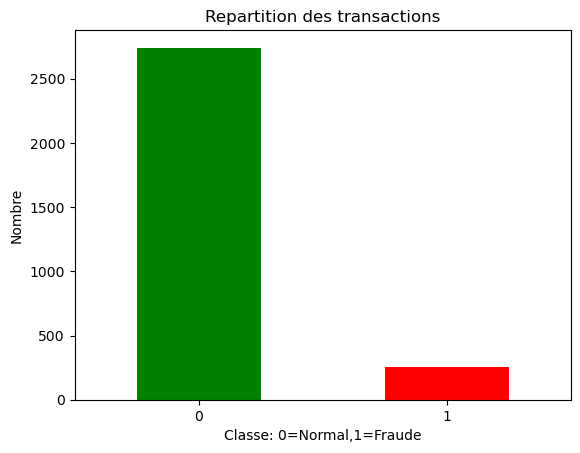

In [11]:
import matplotlib.pyplot as plt
effectifs=df["fraude"].value_counts().sort_index()
pourcentages= df["fraude"].value_counts(normalize=True).sort_index()*100
tableau=pd.DataFrame({"Nombre":effectifs,"Pourcentage":pourcentages})
print(tableau)
tableau["Nombre"].plot(kind="bar",color=["green","red"])
plt.title("Repartition des transactions")
plt.xlabel("Classe: 0=Normal,1=Fraude")
plt.ylabel("Nombre")
plt.xticks(rotation=0)
plt.show()

In [12]:
x=df.drop(columns=["id_operation","id_client","resultat_enquete","fraude"])
y=df["fraude"]
print("Variables explicatives:")
print(x.columns)
print("\nVariable cible:)")
print(y.name)

Variables explicatives:
Index(['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal',
       'appareil', 'region', 'international'],
      dtype='object')

Variable cible:)
fraude


In [13]:
from sklearn.model_selection import train_test_split
x_train,x_temp,y_train,y_temp=train_test_split(x,y,test_size=0.40,random_state=42,
                                               stratify=y)
x_val,x_test,y_val,y_test=train_test_split(
    x_temp,y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp)
print("Train:",x_train.shape)
print("validation:",x_val.shape)
print("Test:",x_test.shape)

Train: (1800, 8)
validation: (600, 8)
Test: (600, 8)


In [14]:
print("Pourcentage de fraude dans train :",y_train.mean()*100)
print("Pourcentage de fraude dans validation:",y_val.mean()*100)
print("Pourcentage de fraude dans test:",y_test.mean()*100)

Pourcentage de fraude dans train : 8.61111111111111
Pourcentage de fraude dans validation: 8.666666666666668
Pourcentage de fraude dans test: 8.5


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

numeriques = x.select_dtypes(include="number").columns
categories = x.select_dtypes(exclude="number").columns

pipeline_num = Pipeline([("imputation",SimpleImputer(strategy="median")),
                       ("standardisation",StandardScaler())
                        ])

pipeline_cat = Pipeline([("imputation",SimpleImputer(strategy="most_frequent")),
                         ("encodage",OneHotEncoder(handle_unknown="ignore"))
                        ])

preprocesseur = ColumnTransformer([
    ("num",pipeline_num,numeriques),
    ("cat",pipeline_cat,categories)
])

x_train_prepare = preprocesseur.fit_transform(x_train)
x_val_prepare = preprocesseur.transform(x_val)
x_test_prepare = preprocesseur.transform(x_test)

In [16]:
print("x_train:",x_train_prepare.shape)
print("x_val:",x_val_prepare.shape)
print("x_test:",x_test_prepare.shape)
print("\nles colonnes transformées:")
print(preprocesseur.get_feature_names_out())
print("\nResultat:")
print(x_train_prepare[:5])

x_train: (1800, 18)
x_val: (600, 18)
x_test: (600, 18)

les colonnes transformées:
['num__montant_dh' 'num__anciennete_mois' 'num__nb_ops_24h' 'num__heure'
 'cat__canal_agence' 'cat__canal_application' 'cat__canal_site_web'
 'cat__canal_telephone' 'cat__appareil_mobile' 'cat__appareil_ordinateur'
 'cat__appareil_terminal' 'cat__region_Autre'
 'cat__region_Casablanca-Settat' 'cat__region_Draa-Tafilalet'
 'cat__region_Marrakech-Safi' 'cat__region_Souss-Massa'
 'cat__international_non' 'cat__international_oui']

Resultat:
[[-0.61105179  1.66356341  1.36120583 -1.34420088  0.          1.
   0.          0.          0.          1.          0.          1.
   0.          0.          0.          0.          1.          0.        ]
 [-0.02260616 -0.41344023  0.75741813  1.66235494  0.          1.
   0.          0.          1.          0.          0.          0.
   0.          0.          1.          0.          1.          0.        ]
 [-0.41629937 -1.13938326 -1.05394497 -0.19884628  1.        

In [17]:
from sklearn .dummy import DummyClassifier
from sklearn.metrics import accuracy_score,recall_score
dummy = Pipeline([
    ("preparation",preprocesseur),
    ("classification",DummyClassifier(strategy="most_frequent"))
])
dummy.fit(x_train,y_train)
pred_dummy = dummy.predict(x_val)
print("Accuracy:",accuracy_score(y_val,pred_dummy))
print("Recall:",recall_score(y_val,pred_dummy,zero_division=0))

Accuracy: 0.9133333333333333
Recall: 0.0


In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,recall_score,f1_score
knn3 = Pipeline([
    ("preparation",preprocesseur),
    ("classification",KNeighborsClassifier(n_neighbors=3))
])
knn11 = Pipeline([
    ("preparation",preprocesseur),
    ("classification",KNeighborsClassifier(n_neighbors=11))
])
knn3.fit(x_train,y_train)
knn11.fit(x_train,y_train)
pred3 = knn3.predict(x_val)
pred11 = knn11.predict(x_val)
print("KNN k=3")
print("Accuracy:",accuracy_score(y_val,pred3))
print("Recall:",recall_score(y_val,pred3,zero_division=0))
print("\nKNN k=11")
print("Accuracy:",accuracy_score(y_val,pred11))
print("Recall:",recall_score(y_val,pred11,zero_division=0))
print("F1:",f1_score(y_val,pred11,zero_division=0))


KNN k=3
Accuracy: 0.905
Recall: 0.0

KNN k=11
Accuracy: 0.9133333333333333
Recall: 0.0
F1: 0.0


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

arbre3 = Pipeline([
    ("preparation",preprocesseur),
    ("classification",DecisionTreeClassifier(max_depth=3,random_state=42))
])
arbre_complet = Pipeline([
    ("preparation",preprocesseur),
    ("classification",DecisionTreeClassifier(
        max_depth=None,
        random_state=42))
])
arbre3.fit(x_train,y_train)
arbre_complet.fit(x_train,y_train)

print("Arbre profondeur 3")
print("F1 Train:",f1_score(y_train,arbre3.predict(x_train),zero_division=0))
print("F1 Validation:",f1_score(y_val,arbre3.predict(x_val),zero_division=0))
print("\nArbre sans limite")
print("F1 Train:",f1_score(y_train,arbre_complet.predict(x_train),zero_division=0))
print("F1 Validation :",f1_score(y_val,arbre_complet.predict(x_val),zero_division=0))

Arbre profondeur 3
F1 Train: 0.050314465408805034
F1 Validation: 0.0

Arbre sans limite
F1 Train: 1.0
F1 Validation : 0.08849557522123894


In [20]:
from sklearn.svm import SVC
svm = Pipeline([
    ("preparation",preprocesseur),
    ("classification",SVC(kernel="linear"))
])
svm.fit(x_train,y_train)
pred_svm = svm.predict(x_val)
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score
print("Accuracy :",accuracy_score(y_val,pred_svm))
print("Precision :",precision_score(y_val,pred_svm,zero_division=0))
print("Recall:",recall_score(y_val,pred_svm,zero_division=0))
print("F1:",f1_score(y_val,pred_svm,zero_division=0))

Accuracy : 0.9133333333333333
Precision : 0.0
Recall: 0.0
F1: 0.0


In [21]:
from sklearn.metrics import(
  accuracy_score,
  precision_score,
  recall_score,
  f1_score)
modeles = {
    "Dummy": dummy,
    "KNN k=3": knn3,
    "KNN k=11":knn11,
    "Arbre profondeur 3": arbre3,
    "Arbre sans limite":arbre_complet,
    "SVM lineaire":svm
}
resultats = []
for nom,modele in modeles.items():
    prediction = modele.predict(x_val)
    resultats.append({
    "Modele":nom ,
    "Accuracy": accuracy_score(y_val,prediction),
    "Precision":precision_score(y_val,prediction,zero_division=0),
    "Recall":recall_score( y_val,prediction,zero_division=0),
        "F1":f1_score(y_val,prediction,zero_division=0)
    })
    
    tableau_comparaison = pd.DataFrame(resultats)
    
    print(tableau_comparaison.sort_values(
        by="F1",ascending=False
    ))
            
    

  Modele  Accuracy  Precision  Recall   F1
0  Dummy  0.913333        0.0     0.0  0.0
    Modele  Accuracy  Precision  Recall   F1
0    Dummy  0.913333        0.0     0.0  0.0
1  KNN k=3  0.905000        0.0     0.0  0.0
     Modele  Accuracy  Precision  Recall   F1
0     Dummy  0.913333        0.0     0.0  0.0
1   KNN k=3  0.905000        0.0     0.0  0.0
2  KNN k=11  0.913333        0.0     0.0  0.0
               Modele  Accuracy  Precision  Recall   F1
0               Dummy  0.913333        0.0     0.0  0.0
1             KNN k=3  0.905000        0.0     0.0  0.0
2            KNN k=11  0.913333        0.0     0.0  0.0
3  Arbre profondeur 3  0.913333        0.0     0.0  0.0
               Modele  Accuracy  Precision    Recall        F1
4   Arbre sans limite  0.828333   0.081967  0.096154  0.088496
0               Dummy  0.913333   0.000000  0.000000  0.000000
1             KNN k=3  0.905000   0.000000  0.000000  0.000000
2            KNN k=11  0.913333   0.000000  0.000000  0.000000


Matrice de confusion:
[[548   0]
 [ 52   0]]


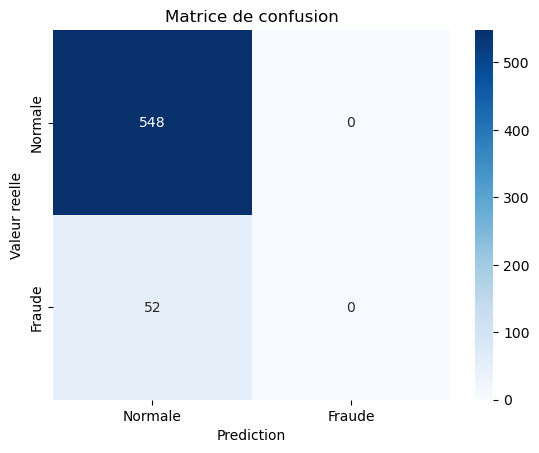

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
prediction = arbre3.predict(x_val)
cm = confusion_matrix(y_val,prediction)
print("Matrice de confusion:")
print(cm)
sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=["Normale","Fraude"],
            yticklabels=["Normale","Fraude"]
)
plt.xlabel("Prediction")
plt.ylabel("Valeur reelle")
plt.title("Matrice de confusion")
plt.show()

In [23]:
VP = 18
FP = 7
FN = 12
VN = 163
accuracy = (VP+VN)/(VP + VN + FP + FN)
precision = VP/(VP + FP)
recall = VP/(VP + FN)
f1 = 2*precision*recall/(precision +recall)
print("Accuracy:",accuracy)
print("Precision:",precision)
print("Recall:",recall)
print("F1-score:",f1)

Accuracy: 0.905
Precision: 0.72
Recall: 0.6
F1-score: 0.6545454545454547


In [24]:
from sklearn.metrics import accuracy_score,recall_score
pred = dummy.predict(x_val)
accuracy = accuracy_score(y_val,pred)
recall = recall_score(y_val,pred,zero_division=0)
print("Accuracy:",accuracy)
print("Recall:",recall)

Accuracy: 0.9133333333333333
Recall: 0.0


In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score,recall_score
arbre = Pipeline([
    ("preparation",preprocesseur),
    ("classification",DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])
arbre.fit(x_train,y_train)
probas= arbre.predict_proba(x_val)[:,1]
for seuil in [0.3,0.5,0.7]:
    prediction = (probas>=seuil).astype(int)
    tn,fp,fn,vp= confusion_matrix(y_val,prediction,labels=[0,1]).ravel()
    print("\nSeuil:",seuil)
    print("FP:",fp)
    print("FN:",fn)

    print("Precision:",precision_score(y_val,prediction,zero_division=0))
    print("Recall:",recall_score(y_val,prediction,zero_division=0))


Seuil: 0.3
FP: 11
FN: 49
Precision: 0.21428571428571427
Recall: 0.057692307692307696

Seuil: 0.5
FP: 0
FN: 52
Precision: 0.0
Recall: 0.0

Seuil: 0.7
FP: 0
FN: 52
Precision: 0.0
Recall: 0.0


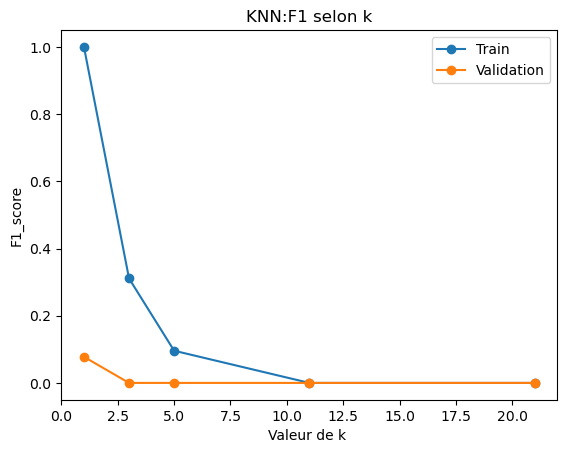

In [26]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

valeurs_k = [1,3,5,11,21]
f1_train=[]
f1_val=[]

for k in valeurs_k:
    modele = Pipeline([
        ("preparation",preprocesseur),
        ("classification",KNeighborsClassifier(n_neighbors=k))
    ])
    modele.fit(x_train,y_train)
    
    pred_train=modele.predict(x_train)
    pred_val=modele.predict(x_val)
    
    f1_train.append(f1_score(y_train,pred_train,zero_division=0))
    f1_val.append(f1_score(y_val,pred_val,zero_division=0))
    
plt.plot(valeurs_k,f1_train,marker="o",label="Train")
plt.plot(valeurs_k,f1_val,marker="o",label="Validation")

plt.xlabel("Valeur de k ")
plt.ylabel("F1_score")
plt.title("KNN:F1 selon k")
plt.legend()
plt.show()

In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
profondeurs=[2,4,8,None]
for profondeur in profondeurs:
    modele= Pipeline([
        ("preparation",preprocesseur),
        ("classification",DecisionTreeClassifier(
            max_depth=profondeur,
            random_state=42
        ))
    ])
    modele.fit(x_train,y_train)
    score_train = f1_score(y_train,modele.predict(x_train),zero_division=0)
    score_val = f1_score(y_val,modele.predict(x_val),zero_division=0)
    print("\nProfondeur:",profondeur)
    print("F1 Train:",score_train)
    print("F1 Validation:",score_val)


Profondeur: 2
F1 Train: 0.0
F1 Validation: 0.0

Profondeur: 4
F1 Train: 0.23076923076923078
F1 Validation: 0.03333333333333333

Profondeur: 8
F1 Train: 0.49760765550239233
F1 Validation: 0.08108108108108109

Profondeur: None
F1 Train: 1.0
F1 Validation: 0.08849557522123894


In [28]:
from sklearn.model_selection import StratifiedKFold,cross_val_score
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
modele = Pipeline([
    ("preparation",preprocesseur),
    ("classification",DecisionTreeClassifier(max_depth=3,random_state=42))
])
scores=cross_val_score(
    modele,
    x_train,
    y_train,
    cv=cv,
    scoring="f1"
)
print("Scores F1:",scores)
print("Moyenne:",scores.mean())
print("Ecart-type:",scores.std())

Scores F1: [0.         0.         0.         0.05714286 0.04878049]
Moyenne: 0.02118466898954704
Ecart-type: 0.02608022665525534


In [29]:
from sklearn.model_selection import GridSearchCV

pipeline_knn = Pipeline([
    ("preparation",preprocesseur),
    ("classification",KNeighborsClassifier())
])
parametres_knn = {
    "classification__n_neighbors":[3,5,9,15]
}
grid_knn = GridSearchCV(
    pipeline_knn,
    param_grid=parametres_knn,
    cv=cv,
    scoring="f1",
    refit=True
)
grid_knn.fit(x_train,y_train)

print("Meilleurs parametres KNN:")
print(grid_knn.best_params_)

print("Meilleur score kNN:")
print(grid_knn.best_score_)

pipeline_arbre = Pipeline([
    ("preparation",preprocesseur),
    ("classification",DecisionTreeClassifier(random_state=42))
])
parametres_arbre = {
    "classification__max_depth":[2,4,6,8]
}
grid_arbre = GridSearchCV(
    pipeline_arbre,
    param_grid=parametres_arbre,
    cv=cv,
    scoring="f1",
    refit=True
)
grid_arbre.fit(x_train,y_train)

print("Meilleurs parametres arbre :")
print(grid_arbre.best_params_)

print("Meilleur score Arbre:")
print(grid_arbre.best_score_)

Meilleurs parametres KNN:
{'classification__n_neighbors': 3}
Meilleur score kNN:
0.05330891330891331
Meilleurs parametres arbre :
{'classification__max_depth': 8}
Meilleur score Arbre:
0.11135352789764555


In [30]:
meilleur_knn = grid_knn.best_estimator_
meilleur_arbre = grid_arbre.best_estimator_

In [31]:
f1_knn = f1_score(
    y_val,
    meilleur_knn.predict(x_val),
    zero_division=0)
f1_arbre = f1_score(
    y_val,
    meilleur_arbre.predict(x_val),
    zero_division=0)
print("F1 KNN:",f1_knn)
print("F1 Arbre:",f1_arbre)

F1 KNN: 0.0
F1 Arbre: 0.08108108108108109


In [32]:
if f1_knn >= f1_arbre:
    modele_final = meilleur_knn
    print("Meilleur modele:KNN")
else:
    modele_final = meilleur_arbre
    print("Meilleur modele:Decision Tree")

Meilleur modele:Decision Tree


In [33]:
x_train_val = pd.concat([x_train,x_val])
y_train_val = pd.concat([y_train,y_val])

modele_final.fit(x_train_val,y_train_val)

,steps,"[('preparation', ...), ('classification', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [34]:
pred_test = modele_final.predict(x_test)

print("F1 Test:",f1_score(
    y_test,
    pred_test,
    zero_division=0
))

F1 Test: 0.058823529411764705


In [35]:
from sklearn.metrics import f1_score
score_validation = max(f1_knn,f1_arbre)
score_test = f1_score(
    y_test,
    pred_test,
    zero_division=0
)
print("F1 validation:",score_validation)
print("F1 Test:",score_test)

F1 validation: 0.08108108108108109
F1 Test: 0.058823529411764705


In [36]:
logements =pd.read_excel("TP3-logements.xlsx")
print(logements.head())

print("\nDimensions:")
print(logements.shape)

print("\nTypes des variables:")
print(logements.dtypes)

print("\nValeurs manquantes:")
print(logements.isnull().sum())
x_reg = logements.drop(columns=["prix_dh","id_logement"]
                      )
y_reg = logements["prix_dh"]

numeriques_reg = x_reg.select_dtypes(
    include="number").columns
categories_reg = x_reg.select_dtypes(
    exclude="number"
).columns

print("\nVariables numeriques:",list(numeriques_reg))
print("Variables categorielles:",list(categories_reg))
print("Variable cible:",y_reg.name)

  id_logement  surface_m2  anciennete_ans  distance_centre_km     quartier  \
0       L0001       105.6            17.0                 8.2  Residentiel   
1       L0002       110.6             9.0                19.5  Residentiel   
2       L0003       134.3             5.0                 1.7   Peripherie   
3       L0004        74.1            19.0                19.5  Residentiel   
4       L0005       146.8            12.0                 4.3  Residentiel   

   prix_dh  
0  1308954  
1  1007062  
2  1375932  
3   800497  
4  1726373  

Dimensions:
(800, 6)

Types des variables:
id_logement            object
surface_m2            float64
anciennete_ans        float64
distance_centre_km    float64
quartier               object
prix_dh                 int64
dtype: object

Valeurs manquantes:
id_logement            0
surface_m2             0
anciennete_ans        41
distance_centre_km    42
quartier              34
prix_dh                0
dtype: int64

Variables numeriques: ['surfac

In [37]:
from sklearn.model_selection import train_test_split

(x_train_reg,x_temp_reg,y_train_reg,
y_temp_reg )= train_test_split(
    x_reg,
    y_reg,
    test_size = 0.40,
    random_state=42
)
(x_val_reg,x_test_reg,y_val_reg,
y_test_reg) = train_test_split(
    x_temp_reg,
    y_temp_reg,
    test_size=0.50,
    random_state=42
)
print("Train :",x_train_reg.shape)
print("Validation:",x_val_reg.shape)
print("Test:",x_test_reg.shape)

Train : (480, 4)
Validation: (160, 4)
Test: (160, 4)


In [38]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

dummy_reg =DummyRegressor(strategy="mean")

dummy_reg.fit(x_train_reg,y_train_reg)

pred_dummy = dummy_reg.predict(x_val_reg)

mae = mean_absolute_error(y_val_reg,pred_dummy)
mse = mean_squared_error(y_val_reg,pred_dummy)
rmse = np.sqrt(mse)

print("MAE :",mae)
print("MSE :",mse)
print("RMSE :",rmse)

MAE : 405418.059375
MSE : 227292019467.8299
RMSE : 476751.52801834827


In [39]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
num_reg=x_reg.select_dtypes(include="number").columns
cat_reg=x_reg.select_dtypes(exclude="number").columns
num_pipeline_reg = Pipeline([
    ("imputer",
     SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])
cat_pipeline_reg = Pipeline([
    ("imputer",
     SimpleImputer(strategy="most_frequent")),
    ("encoder",
     OneHotEncoder(handle_unknown="ignore"))
])
preparation_reg = ColumnTransformer([
    ("num",num_pipeline_reg,num_reg),
    ("cat",cat_pipeline_reg,cat_reg)
])
modele_lineaire = Pipeline([
    ("preparation",preparation_reg),
    ("regression",LinearRegression())
])
modele_lineaire.fit(x_train_reg,y_train_reg)
predictions = modele_lineaire.predict(x_val_reg)
comparaison= pd .DataFrame({
    "Prix reel":y_val_reg.values[:10],
    "Prix predit":predictions[:10]
})
print(comparaison)

   Prix reel   Prix predit
0     569055  4.459630e+05
1    1543048  1.702591e+06
2     566456  4.713942e+05
3    1574941  1.724730e+06
4    1317244  1.260270e+06
5    1583996  1.374191e+06
6    1456212  1.595531e+06
7    2071920  1.948451e+06
8    1570767  1.612439e+06
9     871252  9.666212e+05


In [40]:
from sklearn.metrics import(mean_absolute_error,mean_squared_error,r2_score)
import numpy as np 
mae = mean_absolute_error(y_val_reg,predictions)
mse=mean_squared_error(y_val_reg,predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_val_reg,predictions)
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2:",r2)


MAE: 91847.24869060054
MSE: 15199314943.213049
RMSE: 123285.50175593661
R2: 0.931589969584252


In [41]:
from sklearn .tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error 
import numpy as np
profondeurs = [2,5,None]
for profondeur in profondeurs:
    modele=Pipeline([
        ("preparation",preparation_reg),
        ("regression", DecisionTreeRegressor(
            max_depth=profondeur,
            random_state=42
        ))
    ])
    modele.fit(x_train_reg,y_train_reg)
    pred_train = modele.predict(x_train_reg)
    pred_val = modele.predict(x_val_reg)
    rmse_train = np.sqrt(
    mean_squared_error(y_train_reg,pred_train))
    rmse_val = np.sqrt(
    mean_squared_error(y_val_reg,pred_val)
    )
    print("\nProfondeur:",profondeur)
    print("RMSE Train :",rmse_train)
    print("RMSE validation:",rmse_val)


Profondeur: 2
RMSE Train : 233912.54918915682
RMSE validation: 259868.1461620592

Profondeur: 5
RMSE Train : 116577.80711442743
RMSE validation: 158817.75773339297

Profondeur: None
RMSE Train : 0.0
RMSE validation: 163513.69177644575


In [43]:
trois_logements = x_val_reg.head(3)
prix_predits = modele_lineaire.predict(
    trois_logements
)
resultats = pd.DataFrame({
    "Surface":
    trois_logements["surface_m2"].values,
    "Quartier":
    trois_logements["quartier"].values,
    "Prix reel":y_val_reg.loc[
        trois_logements.index].values,
    "Prix predit":prix_predits
})
resultats["Erreur absolue"] = abs(
    resultats["Prix reel"] -
    resultats["Prix predit"]
)
print(resultats)

   Surface    Quartier  Prix reel   Prix predit  Erreur absolue
0     55.1  Peripherie     569055  4.459630e+05   123092.037690
1    172.2         NaN    1543048  1.702591e+06   159543.279044
2     48.4  Peripherie     566456  4.713942e+05    95061.783591


In [44]:
from sklearn.base import clone
modeles_reg = {
    "Dummy":DummyRegressor(strategy="mean"),
    "LinearRegression":
    LinearRegression(),
    "Arbre profondeur 2":
    DecisionTreeRegressor(
        max_depth=2,random_state=42
    ),
    "Arbre profondeur 5":
    DecisionTreeRegressor(
        max_depth=5,random_state=42
    ),
    "Arbre sans limite":
    DecisionTreeRegressor(
        max_depth=None,random_state=42
    )
}
scores={}
for nom,algorithme in modeles_reg.items():
    modele = Pipeline([
        ("preparation", preparation_reg),
        ("regression", algorithme)
    ])
    modele.fit(x_train_reg,y_train_reg)
    prediction = modele.predict(x_val_reg)
    rmse = np.sqrt(
    mean_squared_error(y_val_reg,prediction)
    )
    scores[nom] = rmse
    print(nom,"RMSE Validation:",rmse)
meilleur_nom = min(scores,key=scores.get)
print("\nMeilleur modele :",meilleur_nom)
meilleur_modele = Pipeline([
    ("preparation", preparation_reg),
    ("regression",clone(modeles_reg[meilleur_nom]))
])
x_train_val_reg = pd.concat([
    x_train_reg,x_val_reg
])
y_train_val_reg = pd.concat([
    y_train_reg,y_val_reg
])
meilleur_modele.fit(
    x_train_val_reg,
    y_train_val_reg
)
pred_test_reg = meilleur_modele.predict(x_test_reg)
mae_test = mean_absolute_error(y_test_reg,pred_test_reg
                              )
mse_test = mean_squared_error(
    y_test_reg,pred_test_reg
)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test_reg,pred_test_reg)

print("\nResultats finaux sur Test")
print("MAE:",mae_test)
print("MSE:",mse_test)
print("RMSE:",rmse_test)
print("R2:",r2_test)

Dummy RMSE Validation: 476751.52801834827
LinearRegression RMSE Validation: 123285.50175593661
Arbre profondeur 2 RMSE Validation: 259868.1461620592
Arbre profondeur 5 RMSE Validation: 158817.75773339297
Arbre sans limite RMSE Validation: 163513.69177644575

Meilleur modele : LinearRegression

Resultats finaux sur Test
MAE: 87660.73251657313
MSE: 14114204969.084087
RMSE: 118803.21952322709
R2: 0.9380154398021487


In [46]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)
train_idx,test_idx = next(
    splitter.split(
        x,
        y,
        groups=df["id_client"]
    )
)
x_train_group = x.iloc[train_idx]
x_test_group = x.iloc[test_idx]

print("Train :",x_train_group.shape)
print("Test:",x_test_group.shape)

Train : (2399, 8)
Test: (601, 8)


In [48]:
svm_balanced = Pipeline([
    ("preparation",preprocesseur),
    ("classification", SVC(
        kernel="linear",
        class_weight = "balanced"
    ))
])
svm_balanced.fit(x_train,y_train)
pred_balanced = svm_balanced.predict(x_val)
print("Precision :",precision_score(y_val,pred_balanced,zero_division=0))
print("Recall:",recall_score(y_val,pred_balanced,zero_division=0))
print("F1:",f1_score(y_val,pred_balanced,zero_division=0))
print("Matrice de confusion:")
print(confusion_matrix(y_val,pred_balanced))

Precision : 0.13076923076923078
Recall: 0.3269230769230769
F1: 0.18681318681318682
Matrice de confusion:
[[435 113]
 [ 35  17]]
